PRCP-1002: Handwritten Digits Recognition

1. Project Introduction

1.1 Objective

The objective of this project is to develop a machine learning model that can recognise handwritten digits from images.

The model will classify handwritten digit images into ten different categories, from 0 to 9.

1.2 Problem Statement

Handwritten digits can look different depending on the person writing them. This makes automatic recognition a challenging task.

In this project, we will use the MNIST dataset to train and evaluate different machine learning models and identify the best-performing classifier.

1.3 Project Goals

Understand and analyse the MNIST dataset.

Explore and visualise handwritten digit images.

Prepare the data for machine learning.

Train multiple classification models.

Compare model performance.

Select the most suitable model.

Document challenges, solutions and recommendations.

## 2. Dataset Understanding

### 2.1 About the MNIST Dataset

MNIST is a widely used dataset for handwritten digit recognition.

It contains 70,000 grayscale images of handwritten digits ranging from 0 to 9.

### 2.2 Dataset Characteristics

- Total images: 70,000
- Training images: 60,000
- Testing images: 10,000
- Image dimensions: 28 × 28 pixels
- Number of classes: 10
- Pixel intensity range: 0 to 255

### 2.3 Training and Testing Data

The training dataset contains 60,000 images used to teach the machine learning models to recognise handwritten digits.

The testing dataset contains 10,000 separate images used to evaluate how well the trained models recognise previously unseen digits.

### 2.4 Pixel Information

Each image contains 28 rows and 28 columns, giving a total of 784 pixels.

Each pixel represents a grayscale intensity value between 0 and 255.

These pixel values are used as input features by machine learning models.

## 2.5 Software Environment and Reproducibility

This project uses Python, TensorFlow/Keras, NumPy, Matplotlib, pandas and scikit-learn. The exact installed versions are displayed below when the notebook is executed. Random seeds are set where supported to improve reproducibility. Execution times can vary by computer, operating system and software version.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Conv2D, MaxPooling2D, Flatten

# Set seeds for repeatable sampling and neural-network initialization.
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

print("Python libraries imported successfully.")
print("NumPy version:", np.__version__)
print("pandas version:", pd.__version__)
print("scikit-learn version:", sklearn.__version__)
print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

Python libraries imported successfully.
NumPy version: 2.5.4
pandas version: 3.1.1
scikit-learn version: 1.9.1
TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:
from tensorflow.keras.datasets import mnist

# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Dataset loaded successfully!")

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Dataset loaded successfully!
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


In [4]:
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


In [5]:
print("First five training labels:")
print(y_train[:5])

First five training labels:
[5 0 4 1 9]


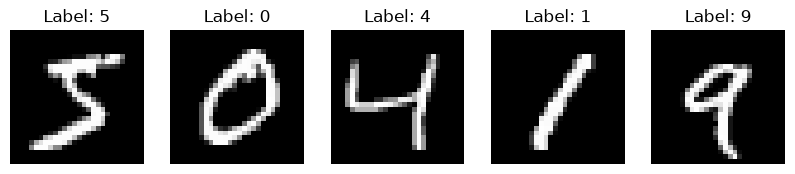

In [6]:
# Display the first five training images
plt.figure(figsize=(10, 3))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()

In [7]:
print("Image shape:", x_train[0].shape)

print("Minimum pixel value:", x_train[0].min())

print("Maximum pixel value:", x_train[0].max())

print("Pixel values of the first 5 rows:")
print(x_train[0][:5])

Image shape: (28, 28)
Minimum pixel value: 0
Maximum pixel value: 255
Pixel values of the first 5 rows:
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]


In [8]:
# Count the number of images for each digit
unique_digits, digit_counts = np.unique(y_train, return_counts=True)

print("Digit distribution in training data:")

for digit, count in zip(unique_digits, digit_counts):
    print(f"Digit {digit}: {count} images")

Digit distribution in training data:
Digit 0: 5923 images
Digit 1: 6742 images
Digit 2: 5958 images
Digit 3: 6131 images
Digit 4: 5842 images
Digit 5: 5421 images
Digit 6: 5918 images
Digit 7: 6265 images
Digit 8: 5851 images
Digit 9: 5949 images


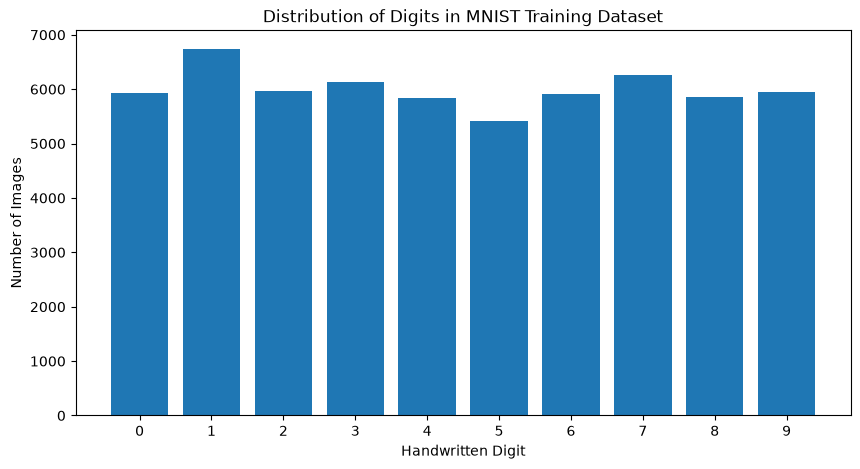

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(unique_digits, digit_counts)

plt.xlabel("Handwritten Digit")
plt.ylabel("Number of Images")
plt.title("Distribution of Digits in MNIST Training Dataset")

plt.xticks(unique_digits)
plt.show()

## Exploratory Data Analysis (EDA)

### 1. Visual Inspection of Images

The first five images from the MNIST training dataset were displayed to understand the appearance of handwritten digits.

Each image has dimensions of 28 × 28 pixels and represents one handwritten digit from 0 to 9.

### 2. Pixel Value Analysis

The MNIST images contain grayscale pixel values ranging from 0 to 255.

- 0 represents black.
- 255 represents white.
- Values between 0 and 255 represent different shades of grey.

Each image contains 784 pixels (28 × 28).

### 3. Distribution of Digit Classes

The training dataset contains 60,000 labelled images across 10 digit classes (0–9).

The class distribution shows:

- Digit 1 has the highest number of images (6,742).
- Digit 5 has the lowest number of images (5,421).
- All 10 digit classes are represented.

The dataset is reasonably balanced, although the number of images varies slightly between classes.

### 4. EDA Conclusion

The initial analysis confirms that the MNIST dataset contains labelled grayscale images suitable for handwritten digit classification.

The image dimensions, pixel values, sample images and class distribution have been examined. This provides a foundation for the next stage of data preprocessing and model development.

In [10]:
# Check the original pixel value range

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Data type:", x_train.dtype)

Minimum pixel value: 0
Maximum pixel value: 255
Data type: uint8


In [11]:
# Normalize pixel values to the range 0 to 1

x_train_normalized = x_train.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

print("Normalization completed!")

print("Training data range:", x_train_normalized.min(), "to", x_train_normalized.max())
print("Testing data range:", x_test_normalized.min(), "to", x_test_normalized.max())

Normalization completed!
Training data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0


In [12]:
print("Training data:")
print("Minimum pixel value:", x_train_normalized.min())
print("Maximum pixel value:", x_train_normalized.max())
print("Data type:", x_train_normalized.dtype)

print("\nTesting data:")
print("Minimum pixel value:", x_test_normalized.min())
print("Maximum pixel value:", x_test_normalized.max())
print("Data type:", x_test_normalized.dtype)

Training data:
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: float32

Testing data:
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: float32


In [13]:
# Flatten each 28 x 28 image into a vector of 784 pixel values

x_train_flattened = x_train_normalized.reshape(len(x_train_normalized), -1)
x_test_flattened = x_test_normalized.reshape(len(x_test_normalized), -1)

print("Training data shape:", x_train_flattened.shape)
print("Testing data shape:", x_test_flattened.shape)

Training data shape: (60000, 784)
Testing data shape: (10000, 784)


In [14]:
print("Original image shape:", x_train_normalized[0].shape)
print("Flattened image shape:", x_train_flattened[0].shape)

print("First 10 pixel values:")
print(x_train_flattened[0][:10])

Original image shape: (28, 28)
Flattened image shape: (784,)
First 10 pixel values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


Data Preprocessing

Data preprocessing was performed to prepare the MNIST dataset for machine learning models.

1. Normalization

The original pixel values ranged from 0 to 255. Both training and testing images were normalized by dividing each pixel value by 255.0.

After normalization, pixel values ranged from 0.0 to 1.0.

2. Flattening

Each MNIST image originally had a shape of 28 × 28 pixels, containing 784 pixel values.

The images were flattened into one-dimensional arrays containing 784 values each.

Training data shape: (60000, 784)

Testing data shape: (10000, 784)

3. Preserving Original Image Structure

The normalized 28 × 28 images were retained separately. The flattened images will be used for traditional machine learning algorithms such as KNN, SVM and Logistic Regression.

The original image structure is retained for the Convolutional Neural Network (CNN).

Conclusion

Normalization and flattening were completed successfully. The dataset is now prepared for the next stage of machine learning model development.

In [15]:
# Verify the preprocessed dataset

print("Training images:", x_train_flattened.shape)
print("Testing images:", x_test_flattened.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 784)
Testing images: (10000, 784)
Training labels: (60000,)
Testing labels: (10000,)


## Dataset Sampling Strategy and Justification

The original MNIST dataset contains 60,000 training images and 10,000 test images. For this project, a stratified development sample of 10,000 images was selected from the original training dataset. A separate stratified sample of 2,000 images was selected from the original test dataset.

The 10,000-image development sample is further divided into:

- **Training set:** 9,000 images
- **Validation set:** 1,000 images

All five models use the same training, validation and test partitions to ensure a fair comparison.

The validation set is used to assess model performance and support model selection. The separate 2,000-image test set is reserved for final model evaluation.

### Reasons for Selecting a Smaller Sample

1. **Computational efficiency:** Training five different machine learning and deep learning models on the complete dataset could require significant computational time and resources. A smaller sample keeps the experiment manageable.
2. **Stratified sampling:** Stratified sampling maintains representation of all ten digit classes (0–9) across the training, validation and test samples.
3. **Fair model comparison:** All five models use the same training, validation and test partitions.

### Limitation of the Sampling Strategy

The reported test results are based on 2,000 images, rather than the complete 10,000-image MNIST test dataset. Therefore, the results represent performance on this selected test sample.

### Future Recommendation

The models should be evaluated on the complete MNIST test dataset and on external handwritten images in future work.

In [16]:
# Create the KNN model

knn_model = KNeighborsClassifier(n_neighbors=5, weights="uniform", metric="minkowski", p=2)

print("KNN model created successfully!")

KNN model created successfully!


In [17]:
# Create one stratified development sample and one untouched test sample

# First select 10,000 images from the original 60,000-image training set.
x_train_sample, _, y_train_sample, _ = train_test_split(
    x_train_flattened,
    y_train,
    train_size=10000,
    stratify=y_train,
    random_state=42
)

# Select 2,000 images from the original 10,000-image test set.
x_test_sample, _, y_test_sample, _ = train_test_split(
    x_test_flattened,
    y_test,
    train_size=2000,
    stratify=y_test,
    random_state=42
)

# Split the 10,000-image development sample into a common 90% training
# set and 10% validation set. All five models use this same split.
x_model_train, x_validation, y_model_train, y_validation = train_test_split(
    x_train_sample,
    y_train_sample,
    test_size=0.10,
    stratify=y_train_sample,
    random_state=42
)

print("Model training sample:", x_model_train.shape)
print("Validation sample:", x_validation.shape)
print("Final test sample:", x_test_sample.shape)

Model training sample: (9000, 784)
Validation sample: (1000, 784)
Final test sample: (2000, 784)


In [18]:
print("Development sample before train/validation split:", x_train_sample.shape)
print("Testing sample:", x_test_sample.shape)
print("Training labels:", y_train_sample.shape)
print("Testing labels:", y_test_sample.shape)

Development sample before train/validation split: (10000, 784)
Testing sample: (2000, 784)
Training labels: (10000,)
Testing labels: (2000,)


In [19]:
print("Model-training digit distribution:")
print(np.bincount(y_model_train))

print("\nValidation digit distribution:")
print(np.bincount(y_validation))

print("\nFinal test digit distribution:")
print(np.bincount(y_test_sample))

Model-training digit distribution:
[ 888 1012  894  920  877  813  887  940  877  892]

Validation digit distribution:
[ 99 112  99 102  97  91  99 104  98  99]

Final test digit distribution:
[196 227 206 202 196 178 192 206 195 202]


In [20]:
# Verify that all five models use the same training, validation and test samples

assert x_model_train.shape == (9000, 784)
assert x_validation.shape == (1000, 784)
assert x_test_sample.shape == (2000, 784)
assert y_model_train.shape == (9000,)
assert y_validation.shape == (1000,)
assert y_test_sample.shape == (2000,)
assert set(np.unique(y_model_train)) == set(range(10))
assert set(np.unique(y_validation)) == set(range(10))
assert set(np.unique(y_test_sample)) == set(range(10))

print("Training images:", x_model_train.shape)
print("Validation images:", x_validation.shape)
print("Test images:", x_test_sample.shape)
print("All ten digit classes are represented in each split.")
print("Sample verification passed.")

Training images: (9000, 784)
Validation images: (1000, 784)
Test images: (2000, 784)
All ten digit classes are represented in each split.
Sample verification passed.


In [21]:
# Train the KNN model

start_time = time.perf_counter()

knn_model.fit(x_model_train, y_model_train)

end_time = time.perf_counter()

knn_training_time = end_time - start_time

print("KNN model training completed!")
print("Training time:", round(knn_training_time, 2), "seconds")

KNN model training completed!
Training time: 0.01 seconds


In [22]:
# Make predictions using the KNN model and measure prediction time

start_time = time.perf_counter()
y_pred_knn = knn_model.predict(x_test_sample)
end_time = time.perf_counter()

knn_prediction_time = end_time - start_time

print("KNN predictions completed!")
print("Prediction time:", round(knn_prediction_time, 4), "seconds")
# Measure validation performance separately from final test performance
y_pred_knn_validation = knn_model.predict(x_validation)


KNN predictions completed!
Prediction time: 0.4885 seconds


In [23]:
# Evaluate KNN model accuracy

knn_accuracy = accuracy_score(y_test_sample, y_pred_knn)

print("KNN Model Accuracy:", round(knn_accuracy * 100, 2), "%")

KNN Model Accuracy: 94.4 %


In [24]:
# Generate KNN classification report

print(classification_report(y_test_sample, y_pred_knn))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       196
           1       0.91      1.00      0.95       227
           2       0.98      0.91      0.95       206
           3       0.92      0.95      0.93       202
           4       0.96      0.92      0.94       196
           5       0.94      0.92      0.93       178
           6       0.97      0.98      0.97       192
           7       0.92      0.94      0.93       206
           8       0.98      0.90      0.94       195
           9       0.90      0.94      0.92       202

    accuracy                           0.94      2000
   macro avg       0.95      0.94      0.94      2000
weighted avg       0.95      0.94      0.94      2000



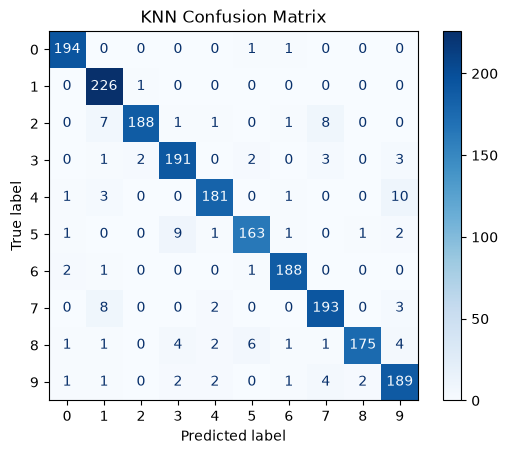

Correct predictions: 1888
Incorrect predictions: 112
Total predictions: 2000


In [25]:
# Create the KNN confusion matrix

cm = confusion_matrix(y_test_sample, y_pred_knn)

knn_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

knn_display.plot(cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.show()

# Count correct and incorrect predictions
print("Correct predictions:", cm.trace())
print("Incorrect predictions:", cm.sum() - cm.trace())
print("Total predictions:", cm.sum())

## K-Nearest Neighbors (KNN) Model Evaluation

The KNN model was trained using the common training partition of 9,000 images and evaluated using the same 2,000 test images used for the other models.

**Model Configuration**

- Number of neighbours (K): 5
- Distance metric: Euclidean distance (Minkowski with p = 2)
- Voting: Uniform weights
- Evaluation metrics: Accuracy, precision, recall and F1-score

The confusion matrix shows the correct and incorrect classifications for each digit.

The exact accuracy, prediction time, correct prediction count and classification report are generated by the executed cells above. These values will be used in the final model comparison rather than copied manually into this explanation.

The results are based on the selected test sample, not the complete MNIST test dataset.

In [26]:
# Analyse the five most common KNN classification errors

error_matrix = cm.copy()

# Remove correct predictions (diagonal)
np.fill_diagonal(error_matrix, 0)

# Find the five largest errors
error_indices = np.dstack(
    np.unravel_index(
        np.argsort(error_matrix.ravel())[-5:][::-1],
        error_matrix.shape
    )
)[0]

print("Five most common classification errors:\n")

for actual, predicted in error_indices:
    print(
        f"Actual digit: {actual}, "
        f"Predicted digit: {predicted}, "
        f"Errors: {error_matrix[actual, predicted]}"
    )

Five most common classification errors:

Actual digit: 4, Predicted digit: 9, Errors: 10
Actual digit: 5, Predicted digit: 3, Errors: 9
Actual digit: 7, Predicted digit: 1, Errors: 8
Actual digit: 2, Predicted digit: 7, Errors: 8
Actual digit: 2, Predicted digit: 1, Errors: 7


In [27]:
# Create the Logistic Regression model

lr_model = LogisticRegression(max_iter=1000, solver="lbfgs", random_state=42)

print("Logistic Regression model created successfully!")

Logistic Regression model created successfully!


In [28]:
# Train the Logistic Regression model

start_time = time.perf_counter()

lr_model.fit(x_model_train, y_model_train)

end_time = time.perf_counter()

lr_training_time = end_time - start_time

print("Logistic Regression training completed!")
print("Training time:", round(lr_training_time, 2), "seconds")

Logistic Regression training completed!
Training time: 19.78 seconds


In [29]:
# Make predictions using Logistic Regression and measure prediction time

start_time = time.perf_counter()
y_pred_lr = lr_model.predict(x_test_sample)
end_time = time.perf_counter()

lr_prediction_time = end_time - start_time

print("Logistic Regression predictions completed!")
print("Prediction time:", round(lr_prediction_time, 4), "seconds")
# Measure validation performance separately from final test performance
y_pred_lr_validation = lr_model.predict(x_validation)


Logistic Regression predictions completed!
Prediction time: 0.0035 seconds


In [30]:
# Evaluate Logistic Regression accuracy

lr_accuracy = accuracy_score(y_test_sample, y_pred_lr)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 90.3 %


In [31]:
# Generate Logistic Regression classification report

print(classification_report(y_test_sample, y_pred_lr))

              precision    recall  f1-score   support

           0       0.91      0.97      0.94       196
           1       0.94      0.97      0.95       227
           2       0.90      0.86      0.88       206
           3       0.87      0.90      0.89       202
           4       0.93      0.91      0.92       196
           5       0.85      0.83      0.84       178
           6       0.93      0.90      0.92       192
           7       0.92      0.92      0.92       206
           8       0.88      0.84      0.86       195
           9       0.90      0.90      0.90       202

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000



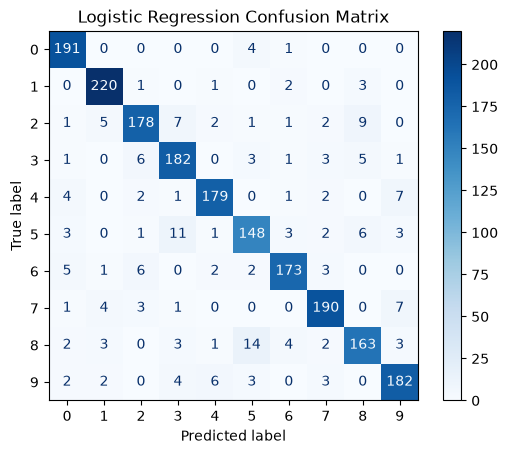

Logistic Regression Confusion Matrix:
[[191   0   0   0   0   4   1   0   0   0]
 [  0 220   1   0   1   0   2   0   3   0]
 [  1   5 178   7   2   1   1   2   9   0]
 [  1   0   6 182   0   3   1   3   5   1]
 [  4   0   2   1 179   0   1   2   0   7]
 [  3   0   1  11   1 148   3   2   6   3]
 [  5   1   6   0   2   2 173   3   0   0]
 [  1   4   3   1   0   0   0 190   0   7]
 [  2   3   0   3   1  14   4   2 163   3]
 [  2   2   0   4   6   3   0   3   0 182]]
Correct predictions: 1806
Incorrect predictions: 194
Total predictions: 2000


In [32]:
# Create Logistic Regression confusion matrix

cm_lr = confusion_matrix(y_test_sample, y_pred_lr)

display_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=range(10)
)

display_lr.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

print("Logistic Regression Confusion Matrix:")
print(cm_lr)

print("Correct predictions:", cm_lr.trace())
print("Incorrect predictions:", cm_lr.sum() - cm_lr.trace())
print("Total predictions:", cm_lr.sum())

In [33]:
# Find the five most common Logistic Regression errors

error_matrix_lr = cm_lr.copy()

# Remove correct predictions
np.fill_diagonal(error_matrix_lr, 0)

# Find the five largest errors
error_indices_lr = np.dstack(
    np.unravel_index(
        np.argsort(error_matrix_lr.ravel())[-5:][::-1],
        error_matrix_lr.shape
    )
)[0]

print("Five most common Logistic Regression errors:\n")

for actual, predicted in error_indices_lr:
    print(
        f"Actual digit: {actual}, "
        f"Predicted digit: {predicted}, "
        f"Errors: {error_matrix_lr[actual, predicted]}"
    )

Five most common Logistic Regression errors:

Actual digit: 8, Predicted digit: 5, Errors: 14
Actual digit: 5, Predicted digit: 3, Errors: 11
Actual digit: 2, Predicted digit: 8, Errors: 9
Actual digit: 7, Predicted digit: 9, Errors: 7
Actual digit: 4, Predicted digit: 9, Errors: 7


## Logistic Regression Model Evaluation

The Logistic Regression model was trained using the common training partition of 9,000 images and evaluated using the same 2,000 test images used for all five models.

**Model Configuration**

- Maximum iterations: 1,000
- Solver: lbfgs
- Regularisation parameter (C): 1.0
- Random state: 42

The executed evaluation cells generate the model's accuracy, training time, prediction time, classification report and confusion matrix. The final comparison will use these results directly.

The confusion matrix and classification report help identify which digit classes are more difficult for this model. All reported values must come from the same clean execution of this notebook.

These results are based on the selected 2,000-image test sample, not the complete MNIST test dataset.

In [34]:
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale")

In [35]:
start_time = time.perf_counter()

svm_model.fit(x_model_train, y_model_train)

end_time = time.perf_counter()

svm_training_time = end_time - start_time

print("SVM training completed.")
print("Training time:", round(svm_training_time, 2), "seconds")

SVM training completed.
Training time: 18.23 seconds


In [36]:
# Make predictions using SVM and measure prediction time

start_time = time.perf_counter()
y_pred_svm = svm_model.predict(x_test_sample)
end_time = time.perf_counter()

svm_prediction_time = end_time - start_time
svm_accuracy = accuracy_score(y_test_sample, y_pred_svm)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")
print("Prediction time:", round(svm_prediction_time, 4), "seconds")
# Measure validation performance separately from final test performance
y_pred_svm_validation = svm_model.predict(x_validation)


SVM Accuracy: 96.1 %
Prediction time: 9.1426 seconds


In [37]:
print(classification_report(y_test_sample, y_pred_svm))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       196
           1       0.96      0.98      0.97       227
           2       0.97      0.98      0.97       206
           3       0.94      0.96      0.95       202
           4       0.97      0.95      0.96       196
           5       0.97      0.96      0.96       178
           6       0.98      0.97      0.97       192
           7       0.96      0.94      0.95       206
           8       0.96      0.96      0.96       195
           9       0.94      0.94      0.94       202

    accuracy                           0.96      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.96      0.96      0.96      2000



## Support Vector Machine (SVM) Model Evaluation

The SVM model was trained using the RBF (Radial Basis Function) kernel on the common training partition of 9,000 images and evaluated using the same 2,000 test images used for all five models.

**Model Configuration**

- Kernel: RBF
- Regularisation parameter (C): 1.0
- Gamma: `scale`

The executed evaluation cells generate the model's test accuracy, training time, prediction time, classification report and confusion matrix. These results will be used in the final model comparison.

The classification report shows the precision, recall and F1-score for each digit. The confusion matrix helps identify which digit classes are more difficult for the SVM model to distinguish.

All reported values are generated from the executed notebook cells.

These results are based on the selected 2,000-image test sample, not the complete MNIST test dataset.

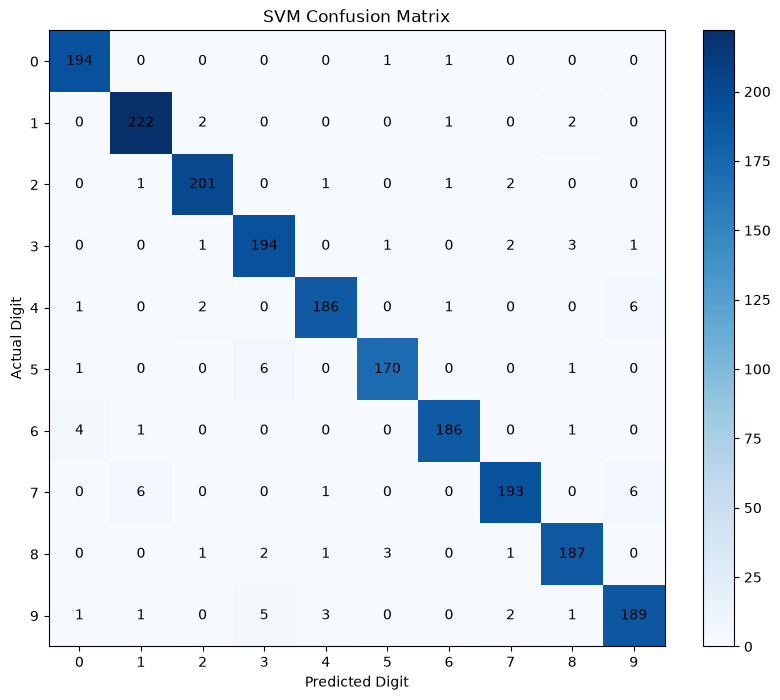

Correct predictions: 1922
Incorrect predictions: 78
Total predictions: 2000


In [38]:
# Calculate confusion matrix
svm_cm = confusion_matrix(y_test_sample, y_pred_svm)

# Display confusion matrix
plt.figure(figsize=(10, 8))
plt.imshow(svm_cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(10))
plt.yticks(range(10))

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("SVM Confusion Matrix")

# Display values inside the matrix
for i in range(10):
    for j in range(10):
        plt.text(j, i, svm_cm[i, j], ha="center", va="center")

plt.show()

print("Correct predictions:", svm_cm.trace())
print("Incorrect predictions:", svm_cm.sum() - svm_cm.trace())
print("Total predictions:", svm_cm.sum())

In [39]:
print(svm_cm)

[[194   0   0   0   0   1   1   0   0   0]
 [  0 222   2   0   0   0   1   0   2   0]
 [  0   1 201   0   1   0   1   2   0   0]
 [  0   0   1 194   0   1   0   2   3   1]
 [  1   0   2   0 186   0   1   0   0   6]
 [  1   0   0   6   0 170   0   0   1   0]
 [  4   1   0   0   0   0 186   0   1   0]
 [  0   6   0   0   1   0   0 193   0   6]
 [  0   0   1   2   1   3   0   1 187   0]
 [  1   1   0   5   3   0   0   2   1 189]]


## SVM Confusion Matrix Analysis

The confusion matrix is generated using the current SVM predictions on the 2,000-image test sample.

The diagonal values represent correctly classified images, while the off-diagonal values represent incorrect predictions.

The following code calculates the number of correct and incorrect predictions and identifies the five most frequent classification errors. This helps us understand which digits the SVM model finds difficult to distinguish.

All results are generated from the current model execution, avoiding the use of results from earlier model runs.

In [40]:
# Summarize the current SVM confusion matrix without hardcoded figures

svm_error_matrix = svm_cm.copy()
np.fill_diagonal(svm_error_matrix, 0)
svm_error_pairs = np.dstack(
    np.unravel_index(
        np.argsort(svm_error_matrix.ravel())[::-1],
        svm_error_matrix.shape
    )
)[0]

print("SVM correct predictions:", int(np.trace(svm_cm)))
print("SVM incorrect predictions:", int(svm_cm.sum() - np.trace(svm_cm)))
print("Five most frequent SVM classification errors:")
shown = 0
for actual_digit, predicted_digit in svm_error_pairs:
    count = int(svm_error_matrix[actual_digit, predicted_digit])
    if count == 0:
        break
    print(f"Actual {actual_digit} predicted as {predicted_digit}: {count}")
    shown += 1
    if shown == 5:
        break

SVM correct predictions: 1922
SVM incorrect predictions: 78
Five most frequent SVM classification errors:
Actual 7 predicted as 9: 6
Actual 7 predicted as 1: 6
Actual 5 predicted as 3: 6
Actual 4 predicted as 9: 6
Actual 9 predicted as 3: 5


In [41]:
ann_model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

In [42]:
ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [43]:
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
start_time = time.perf_counter()

ann_history = ann_model.fit(
    x_model_train,
    y_model_train,
    epochs=10,
    batch_size=128,
    validation_data=(x_validation, y_validation),
    verbose=1
)

end_time = time.perf_counter()

ann_training_time = end_time - start_time

print("ANN training completed.")
print("Training time:", round(ann_training_time, 2), "seconds")

print("Final ANN training accuracy:",
      round(ann_history.history["accuracy"][-1] * 100, 2), "%")
print("Final ANN validation accuracy:",
      round(ann_history.history["val_accuracy"][-1] * 100, 2), "%")
print("Best ANN validation accuracy:",
      round(max(ann_history.history["val_accuracy"]) * 100, 2), "%")

Epoch 1/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7749 - loss: 0.8442 - val_accuracy: 0.9010 - val_loss: 0.3697
Epoch 2/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9076 - loss: 0.3165 - val_accuracy: 0.9240 - val_loss: 0.2801
Epoch 3/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9317 - loss: 0.2419 - val_accuracy: 0.9350 - val_loss: 0.2423
Epoch 4/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9452 - loss: 0.1952 - val_accuracy: 0.9390 - val_loss: 0.2163
Epoch 5/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9549 - loss: 0.1604 - val_accuracy: 0.9360 - val_loss: 0.2015
Epoch 6/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9631 - loss: 0.1341 - val_accuracy: 0.9400 - val_loss: 0.1906
Epoch 7/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9693 - loss: 0.1131 - val_accuracy: 0.9400 - val_loss: 0.1840
Epoch 8/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9756 - loss: 0.0954 - val_accuracy: 0.9440 - val_loss

In [45]:
# Evaluate ANN on the test sample and measure evaluation time

start_time = time.perf_counter()
ann_test_loss, ann_test_accuracy = ann_model.evaluate(
    x_test_sample,
    y_test_sample,
    verbose=0
)
end_time = time.perf_counter()

ann_evaluation_time = end_time - start_time

print("ANN Test Accuracy:", round(ann_test_accuracy * 100, 2), "%")
print("ANN Test Loss:", round(ann_test_loss, 4))
print("Evaluation time:", round(ann_evaluation_time, 4), "seconds")

ANN Test Accuracy: 94.35 %
ANN Test Loss: 0.1686
Evaluation time: 0.4319 seconds


In [46]:
# Generate ANN predictions and measure prediction time

start_time = time.perf_counter()
y_pred_ann_prob = ann_model.predict(
    x_test_sample,
    verbose=0
)
y_pred_ann = y_pred_ann_prob.argmax(axis=1)
end_time = time.perf_counter()

ann_prediction_time = end_time - start_time

print("ANN Prediction Time:", round(ann_prediction_time, 4), "seconds")
print(classification_report(y_test_sample, y_pred_ann))

ANN Prediction Time: 0.7552 seconds
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       196
           1       0.98      0.97      0.98       227
           2       0.97      0.96      0.96       206
           3       0.87      0.95      0.91       202
           4       0.96      0.94      0.95       196
           5       0.95      0.90      0.92       178
           6       0.96      0.95      0.96       192
           7       0.92      0.96      0.94       206
           8       0.95      0.91      0.93       195
           9       0.92      0.92      0.92       202

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000



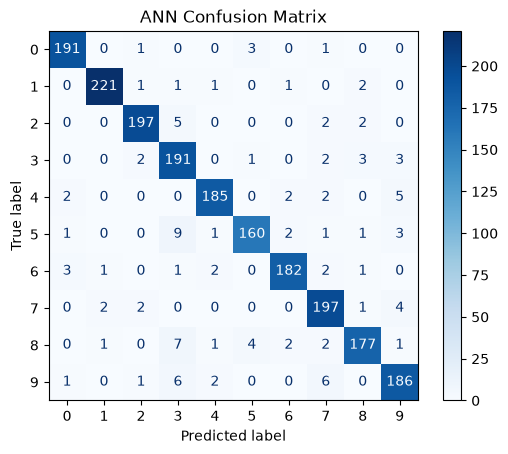

Correct predictions: 1887
Incorrect predictions: 113
Total predictions: 2000


In [47]:
# Create and display the ANN confusion matrix

ann_cm = confusion_matrix(y_test_sample, y_pred_ann)

ann_display = ConfusionMatrixDisplay(
    confusion_matrix=ann_cm,
    display_labels=range(10)
)
ann_display.plot(cmap="Blues")
plt.title("ANN Confusion Matrix")
plt.show()

print("Correct predictions:", int(np.trace(ann_cm)))
print("Incorrect predictions:", int(ann_cm.sum() - np.trace(ann_cm)))
print("Total predictions:", int(ann_cm.sum()))

## 8. ANN (Artificial Neural Network) – Model Evaluation and Confusion Matrix Analysis

### 8.1 Model Overview

An Artificial Neural Network (ANN), also known as a Multi-Layer Perceptron (MLP), was implemented to classify handwritten digits from the MNIST dataset.

The model learns patterns from the input pixel values and uses these patterns to predict the correct digit from 0 to 9.

### 8.2 Model Architecture

The ANN model uses the following layers:

1. Input layer: 784 input features from each flattened image.
2. First hidden layer: 128 neurons with ReLU activation.
3. Second hidden layer: 64 neurons with ReLU activation.
4. Output layer: 10 neurons with Softmax activation for digits 0 to 9.

Total trainable parameters: 109,386.

### 8.3 Training Configuration

- Training images: 9,000
- Validation images: 1,000
- Test images: 2,000
- Epochs: 10
- Batch size: 128
- Validation data: common stratified validation partition
- Optimizer: Adam
- Loss function: Sparse Categorical Crossentropy
- Activation functions: ReLU and Softmax

### 8.4 Model Training and Evaluation

The training cell reports the final training accuracy, final validation accuracy, best validation accuracy and training time. The evaluation cells report test loss, test accuracy, prediction time, classification report and confusion matrix.

These values are generated during notebook execution. They will be used in the final comparison after a successful clean run.

### 8.5 Confusion Matrix Analysis

The confusion matrix and classification report provide a detailed view of the ANN model's performance across all ten digit classes.

The ANN model correctly classified 1,887 out of 2,000 test images, while 113 images were incorrectly classified, giving a test accuracy of 94.35%.

The classification report shows a weighted precision of 0.94, weighted recall of 0.94 and weighted F1-score of 0.94.

The diagonal values in the confusion matrix represent correct predictions, while the values outside the diagonal represent incorrect predictions.

The evaluation is based on the selected test sample of 2,000 images and does not represent evaluation on the complete MNIST test dataset.

In [48]:
x_train_cnn = x_model_train.reshape(9000, 28, 28, 1)
x_validation_cnn = x_validation.reshape(1000, 28, 28, 1)
x_test_cnn = x_test_sample.reshape(2000, 28, 28, 1)

print("CNN training data shape:", x_train_cnn.shape)
print("CNN validation data shape:", x_validation_cnn.shape)
print("CNN testing data shape:", x_test_cnn.shape)

CNN training data shape: (9000, 28, 28, 1)
CNN validation data shape: (1000, 28, 28, 1)
CNN testing data shape: (2000, 28, 28, 1)


In [49]:
cnn_model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation="relu"),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(64, activation="relu"),

    Dense(10, activation="softmax")
])

print("CNN model created successfully.")

CNN model created successfully.


In [50]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully.")


CNN model compiled successfully.


In [51]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 5408)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │         346,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
start_time = time.perf_counter()

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_model_train,
    epochs=10,
    batch_size=128,
    validation_data=(x_validation_cnn, y_validation),
    verbose=1
)

end_time = time.perf_counter()

cnn_training_time = end_time - start_time

print("CNN training completed.")
print("Training time:", round(cnn_training_time, 2), "seconds")

print("Final CNN training accuracy:",
      round(cnn_history.history["accuracy"][-1] * 100, 2), "%")
print("Final CNN validation accuracy:",
      round(cnn_history.history["val_accuracy"][-1] * 100, 2), "%")
print("Best CNN validation accuracy:",
      round(max(cnn_history.history["val_accuracy"]) * 100, 2), "%")

Epoch 1/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8044 - loss: 0.6995 - val_accuracy: 0.9040 - val_loss: 0.3314
Epoch 2/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9190 - loss: 0.2687 - val_accuracy: 0.9390 - val_loss: 0.2320
Epoch 3/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9457 - loss: 0.1876 - val_accuracy: 0.9500 - val_loss: 0.1779
Epoch 4/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9608 - loss: 0.1384 - val_accuracy: 0.9590 - val_loss: 0.1461
Epoch 5/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9699 - loss: 0.1062 - val_accuracy: 0.9650 - val_loss: 0.1264
Epoch 6/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9772 - loss: 0.0841 - val_accuracy: 0.9660 - val_loss: 0.1151
Epoch 7/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9814 - loss: 0.0684 - val_accuracy: 0.9650 - val_loss: 0.1078
Epoch 8/10
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9858 - loss: 0.0558 - val_accuracy: 0.9700 - v

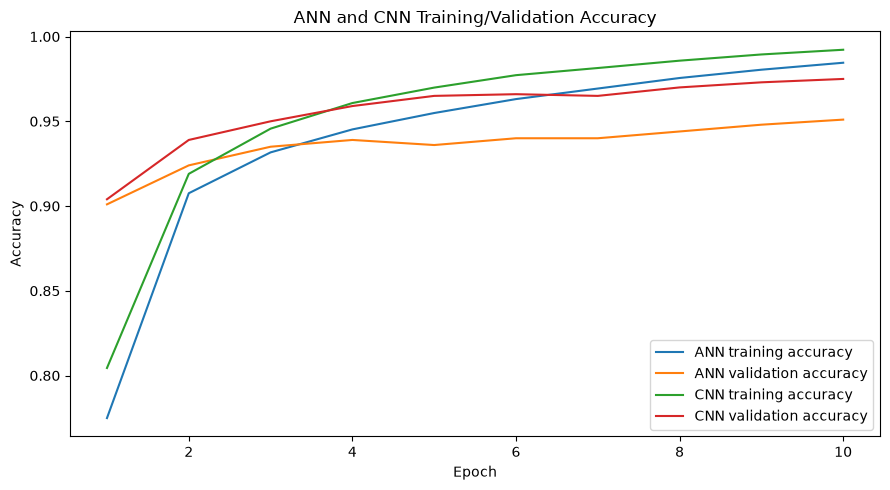

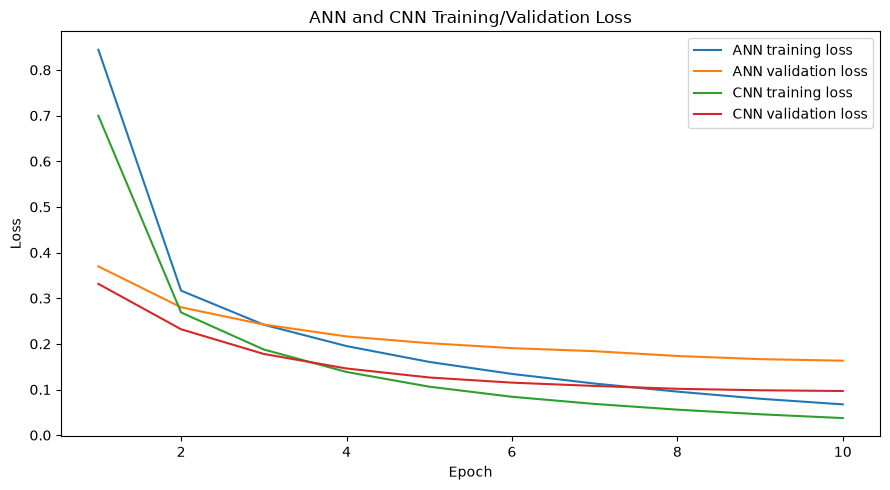

In [53]:
# Plot ANN and CNN learning curves

epochs_ann = range(1, len(ann_history.history["accuracy"]) + 1)
epochs_cnn = range(1, len(cnn_history.history["accuracy"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs_ann, ann_history.history["accuracy"], label="ANN training accuracy")
plt.plot(epochs_ann, ann_history.history["val_accuracy"], label="ANN validation accuracy")
plt.plot(epochs_cnn, cnn_history.history["accuracy"], label="CNN training accuracy")
plt.plot(epochs_cnn, cnn_history.history["val_accuracy"], label="CNN validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN and CNN Training/Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(epochs_ann, ann_history.history["loss"], label="ANN training loss")
plt.plot(epochs_ann, ann_history.history["val_loss"], label="ANN validation loss")
plt.plot(epochs_cnn, cnn_history.history["loss"], label="CNN training loss")
plt.plot(epochs_cnn, cnn_history.history["val_loss"], label="CNN validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN and CNN Training/Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
# Evaluate CNN on the test sample and measure evaluation time

start_time = time.perf_counter()
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    x_test_cnn,
    y_test_sample,
    verbose=0
)
end_time = time.perf_counter()

cnn_evaluation_time = end_time - start_time

print("CNN Test Accuracy:", round(cnn_test_accuracy * 100, 2), "%")
print("CNN Test Loss:", round(cnn_test_loss, 4))
print("Evaluation time:", round(cnn_evaluation_time, 4), "seconds")

CNN Test Accuracy: 97.65 %
CNN Test Loss: 0.0834
Evaluation time: 0.3429 seconds


In [55]:
# Generate CNN predictions and measure prediction time

start_time = time.perf_counter()
y_pred_cnn_prob = cnn_model.predict(
    x_test_cnn,
    verbose=0
)
y_pred_cnn = y_pred_cnn_prob.argmax(axis=1)
end_time = time.perf_counter()

cnn_prediction_time = end_time - start_time

print("CNN Prediction Time:", round(cnn_prediction_time, 4), "seconds")
print(classification_report(y_test_sample, y_pred_cnn))

CNN Prediction Time: 0.4216 seconds
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       196
           1       1.00      0.98      0.99       227
           2       0.97      0.97      0.97       206
           3       0.96      0.98      0.97       202
           4       0.98      0.99      0.99       196
           5       0.98      0.97      0.97       178
           6       0.99      0.97      0.98       192
           7       0.97      0.99      0.98       206
           8       0.97      0.97      0.97       195
           9       0.97      0.96      0.97       202

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



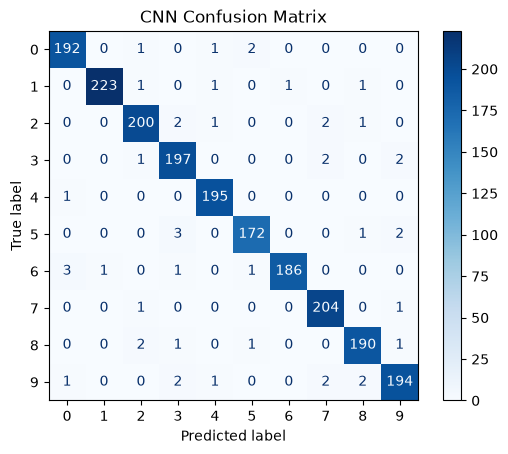

Correct predictions: 1953
Incorrect predictions: 47
Total predictions: 2000


In [56]:
# Create and display the CNN confusion matrix

cnn_cm = confusion_matrix(y_test_sample, y_pred_cnn)

cnn_display = ConfusionMatrixDisplay(
    confusion_matrix=cnn_cm,
    display_labels=range(10)
)
cnn_display.plot(cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.show()

print("Correct predictions:", int(np.trace(cnn_cm)))
print("Incorrect predictions:", int(cnn_cm.sum() - np.trace(cnn_cm)))
print("Total predictions:", int(cnn_cm.sum()))

## 9. CNN (Convolutional Neural Network) – Model Evaluation and Confusion Matrix Analysis

### 9.1 Model Overview

A Convolutional Neural Network (CNN) was implemented to classify handwritten digits from the MNIST dataset.

CNN is suitable for image classification because it can learn image features such as edges, shapes and patterns. It uses the original image structure rather than requiring images to be flattened into one-dimensional arrays.

### 9.2 Model Architecture

The CNN model uses the following layers:

1. Input layer: 28 × 28 × 1 image.
2. Convolutional layer: 32 filters with a 3 × 3 kernel and ReLU activation.
3. Max pooling layer: 2 × 2 pooling window.
4. Flatten layer: converts extracted features into a one-dimensional array.
5. Dense layer: 64 neurons with ReLU activation.
6. Output layer: 10 neurons with Softmax activation for digits 0 to 9.

Total trainable parameters: 347,146.

### 9.3 Training Configuration

- Training images: 9,000
- Validation images: 1,000
- Test images: 2,000
- Epochs: 10
- Batch size: 128
- Validation data: common stratified validation partition
- Optimizer: Adam
- Loss function: Sparse Categorical Crossentropy
- Activation functions: ReLU and Softmax

### 9.4 Model Training and Evaluation

The training cell reports final training accuracy, final validation accuracy, best validation accuracy and training time. The evaluation cells report test loss, test accuracy, prediction time, classification report and confusion matrix.

All figures are generated during execution and must be taken from the same clean run.

### 9.5 Confusion Matrix Analysis

The CNN achieved a test accuracy of **97.65%**, correctly classifying 1,953 out of 2,000 test images. It incorrectly classified 47 images.

The confusion matrix shows the correct and incorrect predictions across all ten digit classes. The diagonal values represent correct predictions, while the values outside the diagonal represent incorrect predictions.

The classification report shows a weighted precision of 0.98, weighted recall of 0.98 and weighted F1-score of 0.98.

The CNN achieved a best validation accuracy of 97.50% and a final validation accuracy of 97.50%.

The evaluation is based on the selected test sample of 2,000 images and does not represent evaluation on the complete MNIST test dataset.

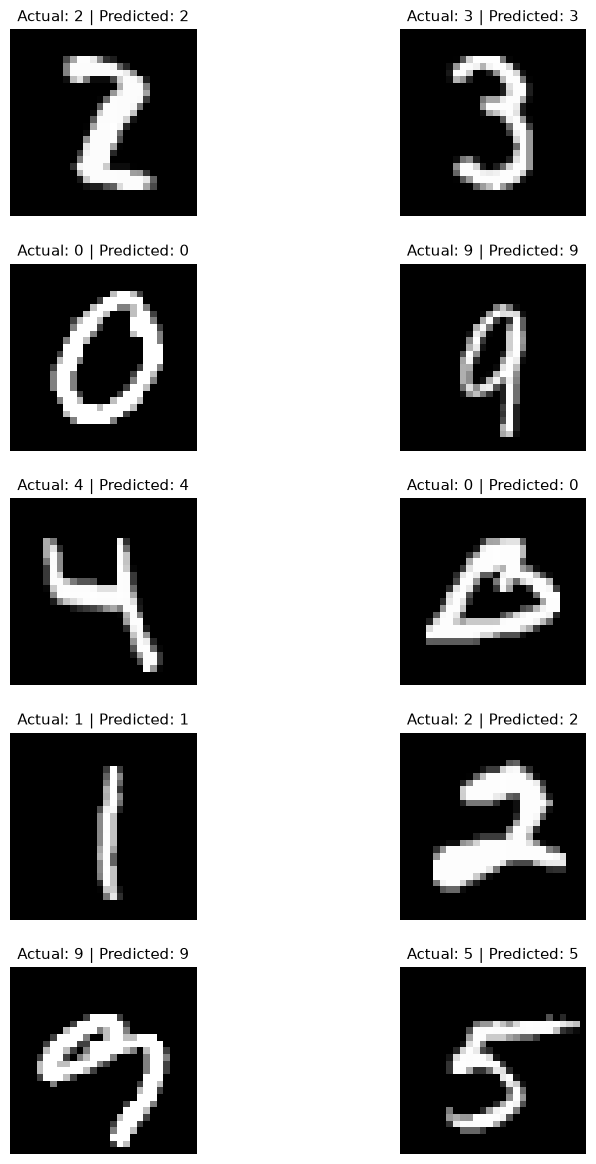

In [57]:
# Display CNN predictions for 10 test images

plt.figure(figsize=(10, 12))

for i in range(10):
    plt.subplot(5, 2, i + 1)

    plt.imshow(x_test_cnn[i].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {y_test_sample[i]} | Predicted: {y_pred_cnn[i]}",
        fontsize=11
    )

    plt.axis("off")

plt.tight_layout(pad=2.0)
plt.show()

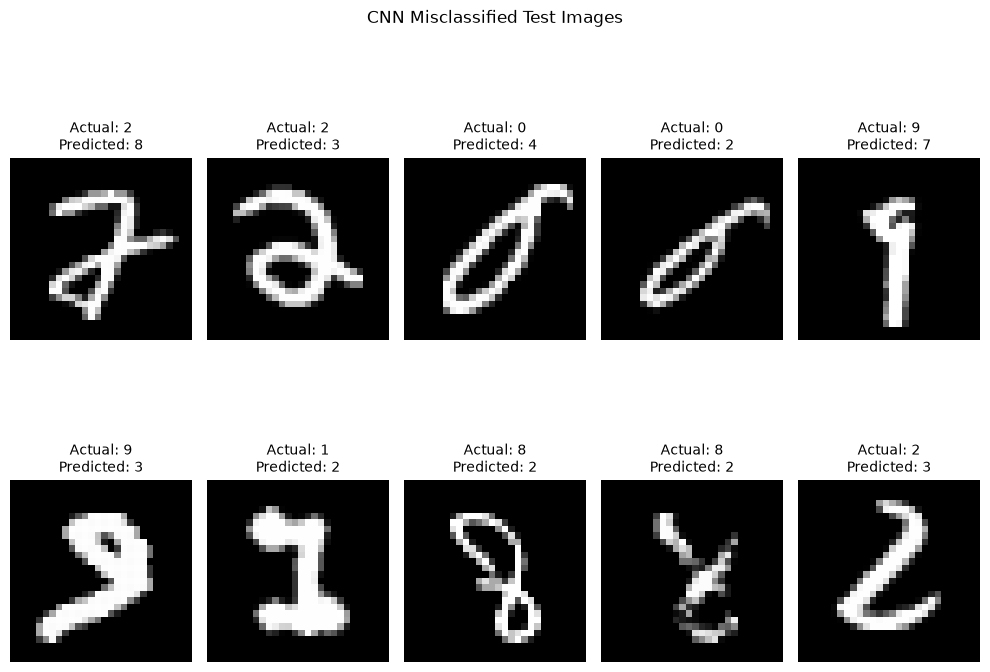

In [58]:
# Display up to 10 CNN test images that were classified incorrectly

misclassified_indices = np.where(y_test_sample != y_pred_cnn)[0][:10]

if len(misclassified_indices) == 0:
    print("No misclassified images were found in this test sample.")
else:
    plt.figure(figsize=(10, 8))
    for plot_position, sample_index in enumerate(misclassified_indices, start=1):
        plt.subplot(2, 5, plot_position)
        plt.imshow(x_test_cnn[sample_index].squeeze(), cmap="gray")
        plt.title(
            f"Actual: {y_test_sample[sample_index]}\nPredicted: {y_pred_cnn[sample_index]}",
            fontsize=10
        )
        plt.axis("off")
    plt.suptitle("CNN Misclassified Test Images")
    plt.tight_layout()
    plt.show()

## Final Model Comparison

The final comparison is generated from predictions and timing variables created during the current notebook execution. All five models use the same 9,000 training images, 1,000 validation images and 2,000 test images.

Training accuracy is calculated from predictions on the common training partition using the final fitted version of each model. Validation accuracy is calculated on the common validation partition. The final test metrics are calculated on the separate test sample.

**The preferred model is selected based on validation accuracy.** Test accuracy and other test metrics are used to evaluate and compare the final performance of the models, rather than to select the model.

Training time and test-set prediction time are measured separately. The additional predictions used to calculate training accuracy are not included in the test-set prediction time. Execution times depend on the computer and software environment.

The confusion matrices are checked against the corresponding prediction arrays before the final comparison is displayed.

In [59]:
# Build the final comparison from the current execution

model_predictions = {
    "KNN": y_pred_knn,
    "Logistic Regression": y_pred_lr,
    "SVM (RBF)": y_pred_svm,
    "ANN (MLP)": y_pred_ann,
    "CNN": y_pred_cnn,
}
model_times = {
    "KNN": (knn_training_time, knn_prediction_time),
    "Logistic Regression": (lr_training_time, lr_prediction_time),
    "SVM (RBF)": (svm_training_time, svm_prediction_time),
    "ANN (MLP)": (ann_training_time, ann_prediction_time),
    "CNN": (cnn_training_time, cnn_prediction_time),
}
model_matrices = {
    "KNN": cm,
    "Logistic Regression": cm_lr,
    "SVM (RBF)": svm_cm,
    "ANN (MLP)": ann_cm,
    "CNN": cnn_cm,
}

# Integrity checks: same test set, one prediction per image, and complete matrices.
for model_name, predictions in model_predictions.items():
    assert len(predictions) == len(y_test_sample) == 2000, model_name
    assert model_matrices[model_name].shape == (10, 10), model_name
    assert int(model_matrices[model_name].sum()) == 2000, model_name
    assert np.array_equal(
        model_matrices[model_name],
        confusion_matrix(y_test_sample, predictions)
    ), f"{model_name}: confusion matrix does not match its predictions"

# Neural-network evaluate() accuracy must agree with accuracy from predict().
assert np.isclose(ann_test_accuracy, accuracy_score(y_test_sample, y_pred_ann), atol=1e-6)
assert np.isclose(cnn_test_accuracy, accuracy_score(y_test_sample, y_pred_cnn), atol=1e-6)

# Calculate training accuracy with the same method for every model.
# These additional predictions are not included in the separately measured
# test-set prediction times shown in the comparison table.
training_predictions = {
    "KNN": knn_model.predict(x_model_train),
    "Logistic Regression": lr_model.predict(x_model_train),
    "SVM (RBF)": svm_model.predict(x_model_train),
    "ANN (MLP)": ann_model.predict(x_model_train, verbose=0).argmax(axis=1),
    "CNN": cnn_model.predict(x_train_cnn, verbose=0).argmax(axis=1),
}
training_accuracy = {
    model_name: accuracy_score(y_model_train, predictions) * 100
    for model_name, predictions in training_predictions.items()
}

validation_accuracy = {
    "KNN": accuracy_score(y_validation, y_pred_knn_validation) * 100,
    "Logistic Regression": accuracy_score(y_validation, y_pred_lr_validation) * 100,
    "SVM (RBF)": accuracy_score(y_validation, y_pred_svm_validation) * 100,
    "ANN (MLP)": ann_history.history["val_accuracy"][-1] * 100,
    "CNN": cnn_history.history["val_accuracy"][-1] * 100,
}
best_validation_accuracy = {
    "ANN (MLP)": max(ann_history.history["val_accuracy"]) * 100,
    "CNN": max(cnn_history.history["val_accuracy"]) * 100,
}
test_loss = {"ANN (MLP)": ann_test_loss, "CNN": cnn_test_loss}

comparison_rows = []
for model_name, predictions in model_predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test_sample, predictions, average="weighted", zero_division=0
    )
    comparison_rows.append({
        "Model": model_name,
        "Test Accuracy (%)": accuracy_score(y_test_sample, predictions) * 100,
        "Correct Predictions": int(np.sum(y_test_sample == predictions)),
        "Incorrect Predictions": int(np.sum(y_test_sample != predictions)),
        "Weighted Precision": precision,
        "Weighted Recall": recall,
        "Weighted F1-score": f1,
        "Training Accuracy (%)": training_accuracy[model_name],
        "Final Validation Accuracy (%)": validation_accuracy[model_name],
        "Best Validation Accuracy (%)": best_validation_accuracy.get(model_name, np.nan),
        "Test Loss": test_loss.get(model_name, np.nan),
        "Training Time (sec)": model_times[model_name][0],
        "Prediction Time (sec)": model_times[model_name][1],
    })

model_results = pd.DataFrame(comparison_rows)
display(model_results.round(4))

best_model_name = model_results.loc[
    model_results["Final Validation Accuracy (%)"].idxmax(), "Model"
]
print("Selected model based on final validation accuracy:", best_model_name)
print("All five models were evaluated on the same 2,000 test images for final comparison.")

,Model,Test Accuracy (%),Correct Predictions,Incorrect Predictions,Weighted Precision,Weighted Recall,Weighted F1-score,Training Accuracy (%),Final Validation Accuracy (%),Best Validation Accuracy (%),Test Loss,Training Time (sec),Prediction Time (sec)
0,KNN,94.40,1888,112,0.9452,0.9440,0.9440,96.4889,94.1,NaN,NaN,0.0077,0.4885
1,Logistic Regression,90.30,1806,194,0.9029,0.9030,0.9026,96.6444,89.4,NaN,NaN,19.7774,0.0035
2,SVM (RBF),96.10,1922,78,0.9611,0.9610,0.9610,98.2778,95.8,NaN,NaN,18.2317,9.1426
3,ANN (MLP),94.35,1887,113,0.9445,0.9435,0.9436,98.5333,95.1,95.1,0.1686,7.8960,0.7552
4,CNN,97.65,1953,47,0.9766,0.9765,0.9765,99.3667,97.5,97.5,0.0834,11.2940,0.4216


Selected model based on final validation accuracy: CNN
All five models were evaluated on the same 2,000 test images for final comparison.


## Consolidated Evaluation and Performance Visualizations

The final comparison table summarizes the performance of all five models using the same training, validation and test partitions.

The following visualizations compare test accuracy and execution time across the five models. They provide a clearer view of the differences in predictive performance and computational cost.

The ANN and CNN learning curves and prediction examples are presented in their respective model sections.

Execution times are measured on the current computer and may vary depending on the hardware and software environment. All charts are generated using results from the current notebook execution.

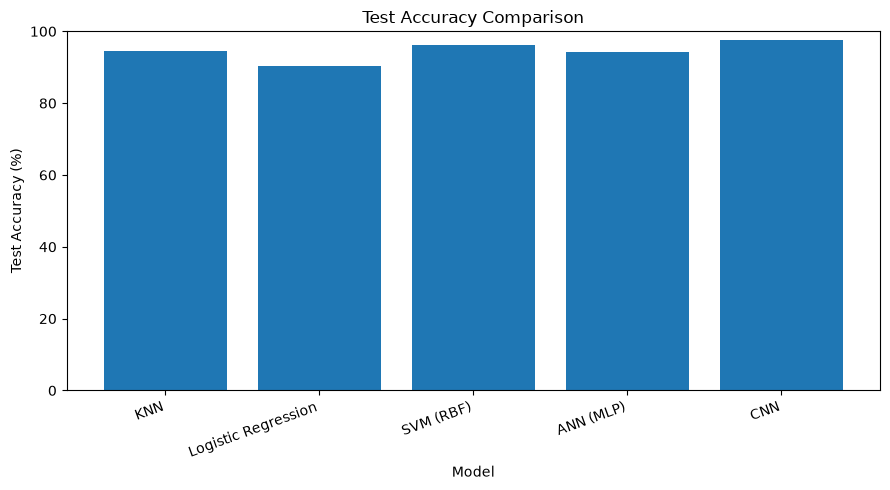

In [60]:
# Compare test accuracy across the five models

plt.figure(figsize=(9, 5))
plt.bar(model_results["Model"], model_results["Test Accuracy (%)"])
plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("Test Accuracy Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

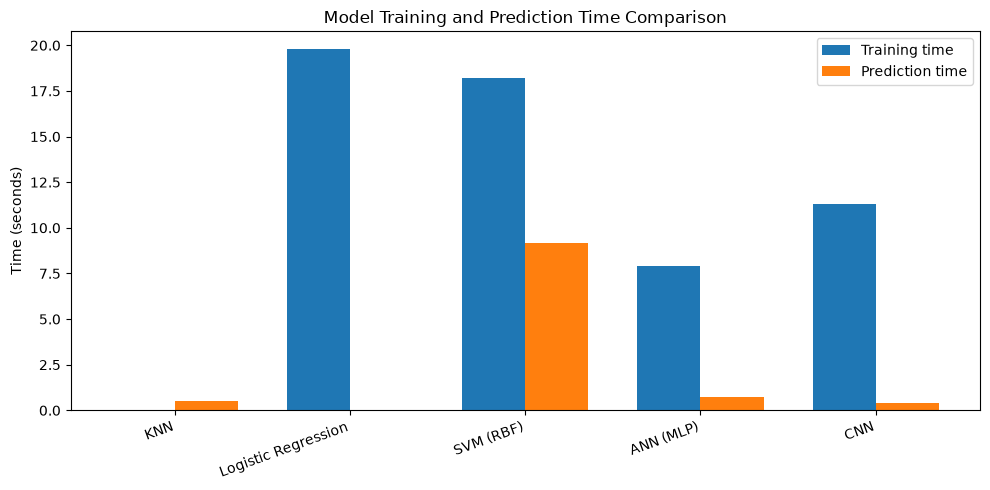

In [61]:
# Compare training and prediction times (seconds)

fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(model_results))
width = 0.36
ax.bar(positions - width / 2, model_results["Training Time (sec)"], width, label="Training time")
ax.bar(positions + width / 2, model_results["Prediction Time (sec)"], width, label="Prediction time")
ax.set_xticks(positions)
ax.set_xticklabels(model_results["Model"], rotation=20, ha="right")
ax.set_ylabel("Time (seconds)")
ax.set_title("Model Training and Prediction Time Comparison")
ax.legend()
plt.tight_layout()
plt.show()

## References

1. LeCun, Y., Cortes, C. and Burges, C. J. C. *The MNIST Database of Handwritten Digits*. http://yann.lecun.com/exdb/mnist/

2. TensorFlow documentation. *MNIST handwritten digit classification dataset*. https://www.tensorflow.org/api_docs/python/tf/keras/datasets/mnist

3. scikit-learn documentation. *KNeighborsClassifier, LogisticRegression, SVC and model evaluation*. https://scikit-learn.org/stable/

4. TensorFlow/Keras documentation. *Sequential models and model training*. https://www.tensorflow.org/guide/keras/sequential_model

5. NumPy documentation. https://numpy.org/doc/

6. Pandas documentation. https://pandas.pydata.org/docs/

7. Matplotlib documentation. https://matplotlib.org/stable/

8. Python documentation. https://docs.python.org/3/

The software versions used for the final execution are recorded in the environment output near the beginning of this notebook.

## AI Tools and Assistance

ChatGPT was used as a learning and development assistant to explain machine-learning concepts, review the notebook structure, troubleshoot coding issues, improve the evaluation methodology and refine project documentation.

The model implementations were executed and evaluated in the project environment. Final reported metrics are based on the outputs generated during the notebook execution.

The project author remains responsible for understanding, checking and explaining the code, methodology and results.

## Final Model Selection

The preferred model is selected using validation accuracy, not test accuracy. This keeps the 2,000-image test sample separate from the model-selection decision. The test metrics are then used to report the final performance of all five trained models.

Based on the current execution, the CNN achieved the highest final validation accuracy of 97.50%, followed by SVM (RBF) at 95.80%. The CNN was therefore selected as the preferred model.

The decision also considers:

1. Correct and incorrect prediction counts on the test sample.
2. Precision, recall and F1-score.
3. Training and prediction time.
4. Model complexity and suitability for the intended application.

The CNN achieved a test accuracy of 97.65%, correctly classifying 1,953 out of 2,000 test images.

The highest validation score does not automatically make a model production-ready. Its test performance, limitations and computational requirements must also be considered. Further testing on a larger and more representative dataset would be needed before production use.

In [62]:
# Select the highest-accuracy model from this execution
best_row = model_results.loc[model_results["Final Validation Accuracy (%)"].idxmax()]
print(f"Preferred model based on validation accuracy: {best_row['Model']}")
print(f"Validation accuracy: {best_row['Final Validation Accuracy (%)']:.2f}%")
print(f"Held-out test accuracy: {best_row['Test Accuracy (%)']:.2f}%")
print(f"Correct test predictions: {int(best_row['Correct Predictions'])} out of {len(y_test_sample)}")
print("Model selection uses the validation sample; the separate test sample provides final evaluation.")

Preferred model based on validation accuracy: CNN
Validation accuracy: 97.50%
Held-out test accuracy: 97.65%
Correct test predictions: 1953 out of 2000
Model selection uses the validation sample; the separate test sample provides final evaluation.


## Limitations and Future Improvements

### Limitations

1. The experiment uses a selected sample from MNIST: 9,000 training images, 1,000 validation images and 2,000 test images. It does not use the complete original dataset for model training and evaluation.
2. MNIST contains small, centered grayscale digit images. Real-world documents may contain different image sizes, backgrounds, rotations, noise and handwriting styles.
3. The model configurations are fixed for this experiment. A broader hyperparameter search could produce different results.
4. Training and prediction times depend on the computer, available hardware and software environment. The neural network models in this experiment were trained using CPU-based TensorFlow.
5. The models have not been deployed or tested in a production application.
6. The results are based on one selected train-validation-test split. Results may vary with different random samples or splits.

### Future Improvements

1. Repeat the experiment using the complete MNIST training and test datasets.
2. Test the selected model on external handwritten digit images collected from different writers.
3. Explore data augmentation and image-cleaning techniques for noisy or rotated images.
4. Perform systematic hyperparameter tuning using validation data.
5. Build an application or API that accepts an image and returns the predicted digit.
6. Measure inference performance on the intended deployment hardware and monitor performance after release.
7. Explore model optimization techniques to reduce inference time and computational requirements.

## Production Recommendation

Based on the validation results, the CNN model is the preferred candidate for further development as a handwritten digit recognition application.

The CNN achieved a final validation accuracy of 97.50% and a held-out test accuracy of 97.65%, correctly classifying 1,953 out of 2,000 test images.

### Possible Real-World Applications

1. Reading handwritten digits on forms and documents.
2. Recognizing postal codes and numeric entries.
3. Digit recognition in scanned documents.
4. Assisting with automated processing of handwritten numeric information.

### Requirements Before Production Deployment

1. Test the model using a larger and more diverse dataset containing different handwriting styles.
2. Evaluate performance on real-world images, including noisy and unclear handwriting.
3. Develop an application interface or API to accept images and return predicted digits.
4. Optimize the model for faster inference and efficient resource usage.
5. Monitor prediction accuracy and update the model when necessary.
6. Test the complete application for reliability, security and error handling.

The model has not been deployed in a real-world environment. Additional validation, application development and performance testing are required before production use.

## Challenges Faced

### Managing Computational Resources

Training and evaluating multiple machine learning and deep learning models on the complete MNIST dataset could require significant computational time and resources.

The original MNIST dataset contains 60,000 training images and 10,000 test images. To keep the experiment manageable, a stratified development sample of 10,000 images was selected from the original training set. This sample was divided into 9,000 training images and 1,000 validation images.

A separate stratified sample of 2,000 images was selected from the original test set for final evaluation.

The same training, validation and test partitions were used for every model to support a fair comparison. Stratified sampling helped maintain representation of all ten digit classes in each partition.

This approach made the experiment manageable, but the results are based on subsets of the original MNIST dataset. Further evaluation using the complete dataset is recommended.

## Project Conclusion

This project explores handwritten digit classification using five approaches: K-Nearest Neighbors (KNN), Logistic Regression, Support Vector Machine (SVM) with an RBF kernel, Artificial Neural Network (ANN/MLP), and Convolutional Neural Network (CNN).

The MNIST dataset is inspected and preprocessed. A stratified development sample of 10,000 images is divided into 9,000 training images and 1,000 validation images. A separate stratified sample of 2,000 test images is reserved for final evaluation. All five models use the same three partitions to support a fair comparison.

The final comparison table and visualizations are generated from the current execution. The CNN achieved the highest final validation accuracy of 97.50% and was selected as the preferred model. It also achieved a test accuracy of 97.65%, correctly classifying 1,953 out of 2,000 test images.

The findings apply only to the selected 2,000-image test sample. They do not establish performance on the complete MNIST dataset or on real-world handwritten documents. Further testing on the complete dataset and external handwriting samples is required before deployment.